# Setup 

In [11]:
import os
import json
import glob
from dataclasses import dataclass
from datetime import datetime

import mne
import numpy as np
import pandas as pd
import scipy.io

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker

# Define Global Parameters 

BANDS = {
    'Delta': (0.5, 4.0),
    'Theta': (4.0, 8.0),
    'Alpha': (8.0, 13.0),
    'Beta': (13.0, 30.0)
}

BAND_COLORS = {
    'Delta': '#1f77b4',
    'Theta': '#2ca02c',
    'Alpha': '#ff7f0e',
    'Beta': '#d62728'
}

BLOCK_COLORS = {
    'REFERENCE': '#fff59d',
    'TEST': '#ffb6c1',
    'CHOICE': '#ffb6c1',
    'CALIBRATION': '#b3e5fc',
    'DEFAULT': '#cbd5e1'
}

# FILE PATHS

FILE_PATH = r'C:\Users\bl104\Downloads\EDF Export (Recording_ bfe729be-af38-4b72-83d1-4c6ed4aa8683).edf'
MAT_DIR = r'C:\Users\bl104\Desktop\mat-files' 
JSON_PATH = r'C:\Users\bl104\Downloads\t17_CALIBRATION_cali_nums.json' 
HYPNO_PATH = r'C:\Users\bl104\Downloads\hypnogram_2026-03-31_15e00d89-44b4-5c06-a1a9-401503de4b2f.csv'


# DATA STRUCTURES

In [12]:
@dataclass
class BlockSpan:
    start_min: float
    end_min: float
    block_id: int
    graph_name: str
    accuracy: float | None
    block_color: str
    mat_path: str

# Loading Functions 

In [13]:
# JSON LOADING

def load_calibration_accuracies(json_path):
    """
    Load calibration accuracies into a lookup dictionary.

    Returns:
        dict[int, float]
    """

    if not json_path or not os.path.exists(json_path):
        print("⚠️ Invalid calibration JSON path.")
        return {}

    try:
        with open(json_path, 'r') as jf:
            json_data = json.load(jf)

        records = (
            json_data
            if isinstance(json_data, list)
            else json_data.get("blocks", [])
        )

        calibration_map = {
            int(item['block_num']): float(item['accuracy'])
            for item in records
            if 'block_num' in item and 'accuracy' in item
        }

        print(f"📊 Loaded {len(calibration_map)} calibration entries.")
        return calibration_map

    except Exception as e:
        print(f"⚠️ Failed to parse calibration JSON: {e}")
        return {}

# HYPNOGRAM LOADING

def load_hypnogram(csv_path):
    """
    Load and vectorize hypnogram staging labels.

    Returns:
        dict with:
            time_minutes
            stages
            labels
    """

    if not csv_path or not os.path.exists(csv_path):
        print("⚠️ Invalid hypnogram CSV path.")
        return None

    try:
        df = pd.read_csv(csv_path, header=None)

        raw_labels = (
            df[0]
            .astype(str)
            .str.strip('" ')
        )

        stage_mapping = {
            "W": 4,
            "REM": 3,
            "R": 3,
            "N1": 2,
            "N2": 1,
            "N3": 0
        }

        numerical_stages = (
            raw_labels
            .map(stage_mapping)
            .fillna(-1)
            .to_numpy()
        )

        time_axis = np.arange(len(numerical_stages)) * 0.5

        print(f"📈 Loaded hypnogram with {len(numerical_stages)} epochs.")

        return {
            'time_minutes': time_axis,
            'stages': numerical_stages,
            'labels': raw_labels.to_numpy()
        }

    except Exception as e:
        print(f"⚠️ Failed to parse hypnogram: {e}")
        return None


# .MAT File Helpers

In [14]:
def load_mat_file(mat_path):
    """
    Lightweight MAT loader.

    Returns:
        dict
    """

    try:
        return scipy.io.loadmat(mat_path)

    except Exception as e:
        print(f"⚠️ Failed to load MAT file: {mat_path}")
        print(e)
        return None


def extract_mat_metadata(mat_data):
    """
    Extract commonly-used metadata from MAT file.

    Returns:
        dict
    """

    redis_clocks = mat_data["binned_neural_redis_clock"][0]

    return {
        'redis_clocks': redis_clocks,
        'block_id': int(mat_data["block_number"][0][0]),
        'graph_name': str(mat_data["graph_name"][0]).upper(),
        'start_dt': datetime.fromtimestamp(redis_clocks[0] / 1000.0),
        'end_dt': datetime.fromtimestamp(redis_clocks[-1] / 1000.0)
    }


def determine_block_color(graph_name, accuracy):
    """
    Determine block visualization color.
    """

    if "REFERENCE" in graph_name:
        return BLOCK_COLORS['REFERENCE']

    if "TEST" in graph_name or "CHOICE" in graph_name:
        return BLOCK_COLORS['TEST']

    if accuracy is not None:
        return BLOCK_COLORS['CALIBRATION']

    return BLOCK_COLORS['DEFAULT']

# Analysis Functions

In [15]:
# EDF AND MAT ALIGNMENT

def calculate_edf_aligned_spans(
    mat_directory,
    edf_start_dt,
    calibration_map=None
):
    """
    Align MAT block timestamps onto EDF-relative timeline.

    Returns:
        list[BlockSpan]
    """

    if calibration_map is None:
        calibration_map = {}

    search_path = os.path.join(mat_directory, "*.mat")
    mat_files = sorted(glob.glob(search_path))

    if not mat_files:
        print(f"⚠️ No MAT files found in: {mat_directory}")
        return []

    if edf_start_dt.tzinfo is not None:
        edf_start_dt = edf_start_dt.replace(tzinfo=None)

    aligned_spans = []

    print(f"\n⏰ Aligning MAT blocks to EDF timeline...")

    for mat_path in mat_files:

        try:
            mat_data = load_mat_file(mat_path)

            if mat_data is None:
                continue

            metadata = extract_mat_metadata(mat_data)

            start_min = (
                metadata['start_dt'] - edf_start_dt
            ).total_seconds() / 60.0

            end_min = (
                metadata['end_dt'] - edf_start_dt
            ).total_seconds() / 60.0

            accuracy = calibration_map.get(
                metadata['block_id']
            )

            block_color = determine_block_color(
                metadata['graph_name'],
                accuracy
            )

            if "REFERENCE" in metadata['graph_name']:
                accuracy = None

            span = BlockSpan(
                start_min=start_min,
                end_min=end_min,
                block_id=metadata['block_id'],
                graph_name=metadata['graph_name'],
                accuracy=accuracy,
                block_color=block_color,
                mat_path=mat_path
            )

            aligned_spans.append(span)

            print(
                f"📍 B.{span.block_id} | "
                f"{span.start_min:.2f} → {span.end_min:.2f} min"
            )

        except Exception as e:
            print(f"⚠️ Failed parsing MAT file: {mat_path}")
            print(e)

    return aligned_spans

# EEG PREPROCESSING

def preprocess_eeg(
    file_path,
    low_cut=0.5,
    high_cut=40.0,
    notch_freqs=(50, 60),
    reference='average'
):
    """
    Load and preprocess EDF EEG data.
    """

    print("\n🔄 Loading EEG data...")

    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

    eeg_channels = [
        ch for ch in raw.ch_names
        if 'ACCELEROMETER' not in ch.upper()
        and 'GYRO' not in ch.upper()
    ]

    raw.pick(eeg_channels)

    raw.rename_channels(
        lambda x: x.strip().upper()
    )

    raw.set_channel_types(
        {ch: 'eeg' for ch in raw.ch_names},
        verbose=False
    )

    raw.filter(
        l_freq=low_cut,
        h_freq=high_cut,
        fir_design='firwin',
        verbose=False
    )

    raw.notch_filter(
        freqs=list(notch_freqs),
        verbose=False
    )

    raw.set_eeg_reference(
        reference,
        projection=False,
        verbose=False
    )

    print(f"✅ Preprocessing complete.")
    print(f"📡 Channels: {len(raw.ch_names)}")

    return raw

# BAND POWER ANALYSIS

def calculate_band_powers(
    raw,
    bands,
    epoch_duration=5.0,
    smoothing_minutes=0.5,
    method='welch',
    relative=True
):
    """
    Compute smoothed EEG band power timelines.

    Returns:
        dict
    """

    print("🧠 Calculating band powers...")

    epochs = mne.make_fixed_length_epochs(
        raw,
        duration=epoch_duration,
        preload=True,
        verbose=False
    )

    spectrum = epochs.compute_psd(
        method=method,
        fmin=0.5,
        fmax=40.0,
        verbose=False
    )

    psds, freqs = spectrum.get_data(return_freqs=True)

    global_psds = np.mean(psds, axis=1)

    total_power = np.sum(global_psds, axis=1)

    smoothing_window = int(
        smoothing_minutes * (60.0 / epoch_duration)
    )

    if smoothing_window < 1:
        raise ValueError(
            "smoothing_minutes is too small for the selected epoch_duration. "
            f"Got smoothing_minutes={smoothing_minutes}, "
            f"epoch_duration={epoch_duration}, "
            f"which gives smoothing_window={smoothing_window}."
        )

    smoothed_timeline = {}
    session_averages = {}

    for band_name, (fmin, fmax) in bands.items():

        freq_idx = np.where(
            (freqs >= fmin) & (freqs <= fmax)
        )[0]

        band_power = np.sum(
            global_psds[:, freq_idx],
            axis=1
        )

        if relative:
            band_power = (
                band_power / total_power
            ) * 100

        smoothed = (
            pd.Series(band_power)
            .rolling(
                window=smoothing_window,
                min_periods=1,
                center=True
            )
            .mean()
            .to_numpy()
        )

        smoothed_timeline[band_name] = smoothed
        session_averages[band_name] = np.mean(band_power)

    edf_start_dt = raw.info['meas_date']

    if edf_start_dt.tzinfo is not None:
        edf_start_dt = edf_start_dt.replace(tzinfo=None)

    return {
        'timeline': smoothed_timeline,
        'summary': session_averages,
        'duration_seconds': raw.times[-1],
        'edf_start_dt': edf_start_dt,
        'freqs': freqs
    }

# VISUALIZATION

In [16]:
def plot_session_summary(
    timeline,
    summary,
    total_duration,
    block_spans,
    edf_anchor_time,
    hypnogram=None
):
    """
    Plot synchronized EEG + task + hypnogram timeline.
    """

    print("📊 Generating plots...")

    max_minutes = total_duration / 60

    time_axis = np.linspace(
        0,
        max_minutes,
        len(next(iter(timeline.values())))
    )

    border_color = '#cfd8dc'

    has_hypnogram = hypnogram is not None

    if has_hypnogram:

        fig, (ax1, ax2) = plt.subplots(
            2,
            1,
            figsize=(16, 10),
            sharex=True,
            gridspec_kw={'height_ratios': [3, 1.2]}
        )

    else:

        fig, ax1 = plt.subplots(
            figsize=(16, 8)
        )

        ax2 = ax1

    # EEG BAND TIMELINES
    
    for band_name, data_points in timeline.items():

        ax1.plot(
            time_axis,
            data_points,
            label=band_name,
            color=BAND_COLORS[band_name],
            linewidth=2
        )

    # BLOCK OVERLAYS
    
    for idx, span in enumerate(block_spans):

        if (
            span.start_min <= (max_minutes + 20)
            and span.end_min >= -10
        ):

            ax1.axvspan(
                span.start_min,
                span.end_min,
                color=span.block_color,
                alpha=0.35
            )

            ax1.axvline(
                span.start_min,
                linestyle='--',
                color=border_color,
                alpha=0.6,
                linewidth=1
            )

            ax1.axvline(
                span.end_min,
                linestyle='--',
                color=border_color,
                alpha=0.6,
                linewidth=1
            )

            label = (
                f"B.{span.block_id}\n{span.accuracy:.1f}%"
                if span.accuracy is not None
                else f"B.{span.block_id}"
            )

            y_pos = 102.5 if idx % 2 == 0 else 107.5

            ax1.text(
                (span.start_min + span.end_min) / 2,
                y_pos,
                label,
                ha='center',
                va='center',
                fontsize=8,
                weight='bold',
                bbox=dict(
                    facecolor='white',
                    alpha=0.95,
                    edgecolor=border_color,
                    boxstyle='round,pad=0.4'
                )
            )

    # AXIS FORMATTING
    
    ax1.set_title(
        "Time-Resolved Relative Power Timeline",
        fontsize=14,
        fontweight='bold'
    )

    ax1.set_ylabel("Relative Power (%)")

    ax1.set_xlim(-10, max_minutes + 20)
    ax1.set_ylim(0, 112)

    ax1.set_yticks([0, 20, 40, 60, 80, 100])

    # LEGEND

    eeg_handles = [
        plt.Line2D(
            [0],
            [0],
            color=BAND_COLORS[band],
            lw=3,
            label=band
        )
        for band in timeline.keys()
    ]

    block_legend_map = {
        'Reference': BLOCK_COLORS['REFERENCE'],
        'Calibration': BLOCK_COLORS['CALIBRATION'],
        'Calibration-Test': BLOCK_COLORS['TEST'],
        'Communication': BLOCK_COLORS['DEFAULT']
    }

    block_handles = [
        mpatches.Patch(
            color=color,
            alpha=0.75,
            label=label
        )
        for label, color in block_legend_map.items()
    ]

    all_handles = eeg_handles + block_handles

    ax1.legend(
        handles=all_handles,
        loc='upper right',
        ncol=2,
        frameon=True,
        columnspacing=1.8,
        handlelength=2.0
    )

    # HYPNOGRAM
    
    if has_hypnogram:

        ax2.step(
            hypnogram['time_minutes'],
            hypnogram['stages'],
            where='mid',
            color='#1e293b',
            linewidth=2
        )

        ax2.set_ylabel("Sleep Stage")

        ax2.set_ylim(-0.5, 4.5)

        ax2.set_yticks([0, 1, 2, 3, 4])

        ax2.set_yticklabels([
            'N3',
            'N2',
            'N1',
            'REM',
            'Wake'
        ])

    # X AXIS
    
    ax2.xaxis.set_major_locator(
        ticker.MultipleLocator(50)
    )

    ticks = [
        t for t in ax2.get_xticks()
        if 0 <= t <= max_minutes
    ]

    start_time_str = edf_anchor_time.strftime('%H:%M:%S')

    labels = [
        f"0\n(Start: {start_time_str})"
        if t == 0
        else f"{int(t)}"
        for t in ticks
    ]

    ax2.set_xticks(ticks)

    ax2.set_xticklabels(labels)

    ax2.set_xlabel("Session Timeline (Minutes)")

    plt.tight_layout()
    plt.show()

    # SESSION SUMMARY BAR CHART
    
    fig2, ax3 = plt.subplots(figsize=(4,4))

    bands = list(summary.keys())
    averages = list(summary.values())

    bars = ax3.bar(
        bands,
        averages,
        color=[BAND_COLORS[b] for b in bands],
        alpha=0.85,
        edgecolor='#374151',
        width=0.55
    )

    ax3.set_title(
        "Overall Session Average",
        fontsize=13,
        fontweight='bold'
    )

    ax3.set_ylabel("Average Relative Power (%)")

    ax3.set_ylim(0, 100)

    for bar in bars:

        yval = bar.get_height()

        ax3.text(
            bar.get_x() + bar.get_width()/2,
            yval + 2,
            f"{yval:.1f}%",
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

    return fig, fig2

# Execution


🔄 Loading EEG data...
✅ Preprocessing complete.
📡 Channels: 5
🧠 Calculating band powers...
📊 Loaded 1 calibration entries.
📈 Loaded hypnogram with 677 epochs.

⏰ Aligning MAT blocks to EDF timeline...
📍 B.2 | -7.13 → -4.09 min
📍 B.3 | -2.13 → 3.43 min
📍 B.4 | 10.95 → 13.77 min
📍 B.5 | 20.59 → 124.95 min
📍 B.6 | 126.65 → 134.46 min
📍 B.7 | 136.61 → 139.42 min
📍 B.9 | 148.05 → 158.78 min
📍 B.10 | 160.04 → 180.33 min
📍 B.11 | 182.22 → 185.26 min
📍 B.12 | 187.98 → 363.28 min
📍 B.13 | 365.47 → 494.83 min
📊 Generating plots...


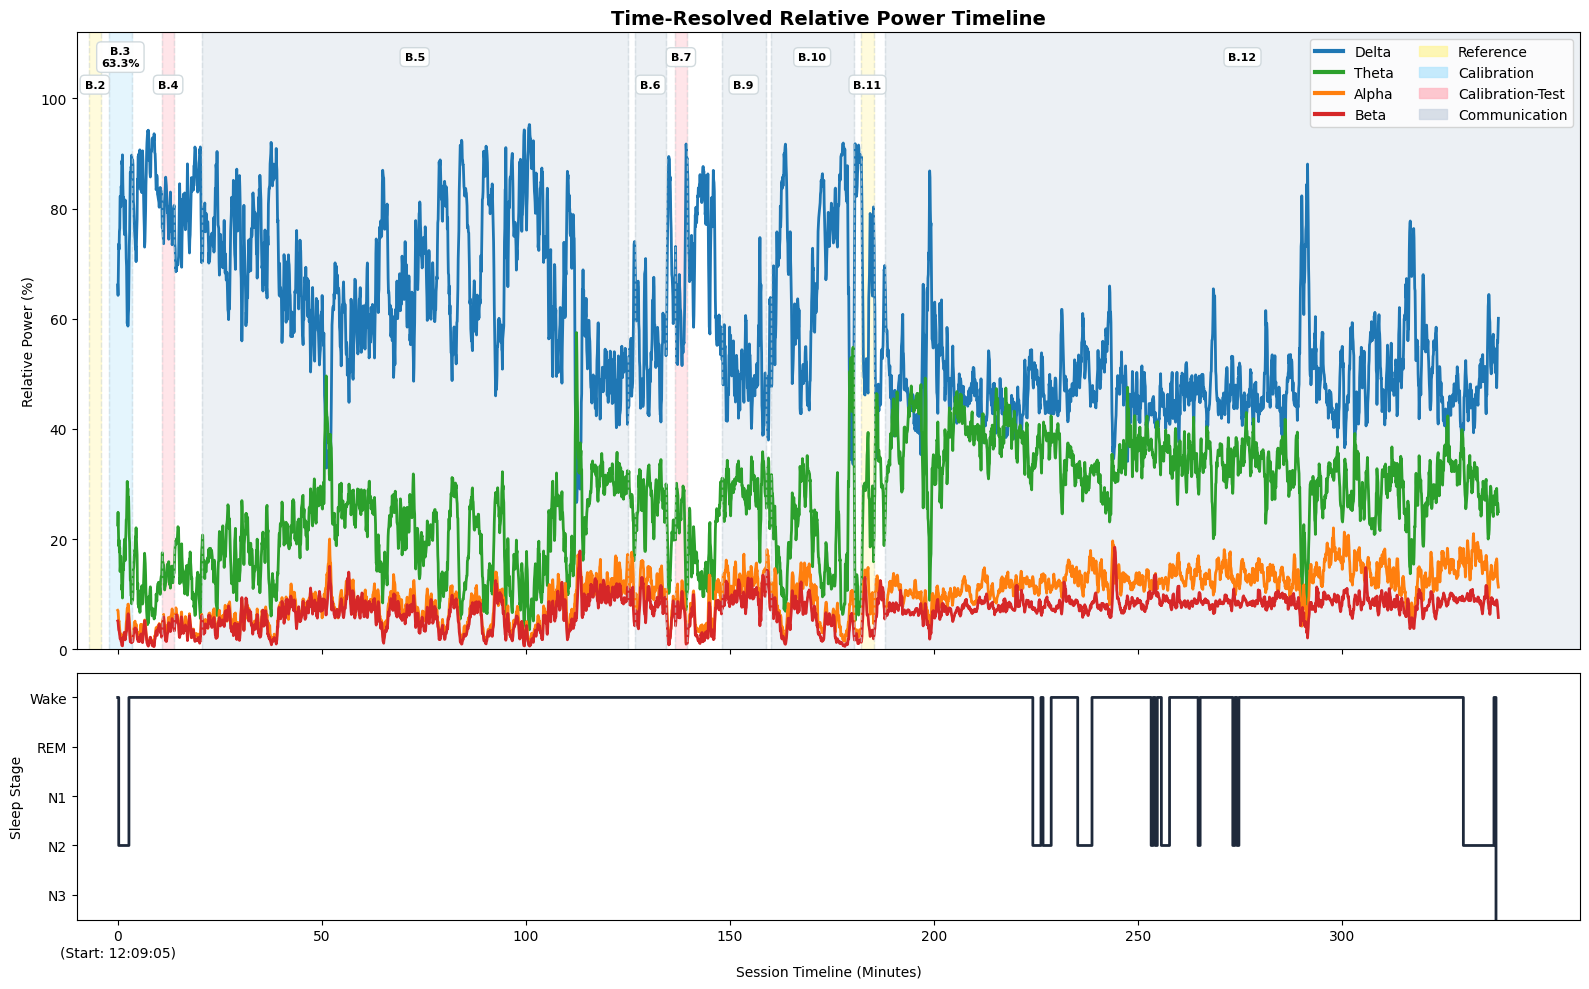

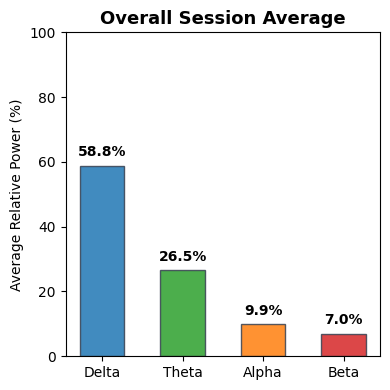

In [ ]:
if __name__ == "__main__":

    # LOAD + PREPROCESS EEG

    raw_data = preprocess_eeg(FILE_PATH)

    # BAND POWER ANALYSIS

    band_results = calculate_band_powers(
        raw=raw_data,
        bands=BANDS,
        epoch_duration=5.0,
        smoothing_minutes=0.5
    )

    # LOAD ACCURACY AND HYPNOGRAM DATA

    calibration_map = load_calibration_accuracies(
        JSON_PATH
    )

    hypnogram = load_hypnogram(
        HYPNO_PATH
    )

    # ALIGN MAT BLOCKS

    block_spans = calculate_edf_aligned_spans(
        MAT_DIR,
        band_results['edf_start_dt'],
        calibration_map
    )

    # VISUALIZE
    
    plot_session_summary(
        timeline=band_results['timeline'],
        summary=band_results['summary'],
        total_duration=band_results['duration_seconds'],
        block_spans=block_spans,
        edf_anchor_time=band_results['edf_start_dt'],
        hypnogram=hypnogram
    )